In [1]:
import numpy as np
import cv2
import tifffile
import matplotlib.pyplot as plt
# from PIL import Image

In [2]:

RGB = "D:/geoinformatics/MajorProject/main/highres_patches/rgbpatchesarcu16/rgbniru16_Clip1_0_0.tif"
PAN = "D:/geoinformatics/MajorProject/main/highres_patches/panpatchesarcu16/WG_PAN_CLIP_BLOCK_0_0.tif"
PANSHARP = "D:/geoinformatics/MajorProject/main/output_tif/bymethods/Bicubic/georef/georef_Bicubic_0_0.tif"

# # # Load RGB image
rgb_image = tifffile.imread(RGB)
# print(rgb_image.dtype)
rgb_image = rgb_image[:, :, ::-1]

# Load panchromatic image
panchromatic_image = tifffile.imread(PAN)  

# Load pansharpened image
pansharpened_image = tifffile.imread(PANSHARP)  
pansharpened_image = pansharpened_image[:, :, ::-1]  

print(rgb_image.shape,"&",rgb_image.dtype)
print(panchromatic_image.shape,"&",panchromatic_image.dtype)
print(pansharpened_image.shape,"&",pansharpened_image.dtype)

(512, 512, 4) & uint16
(1024, 1024) & uint16
(1024, 1024, 4) & uint8


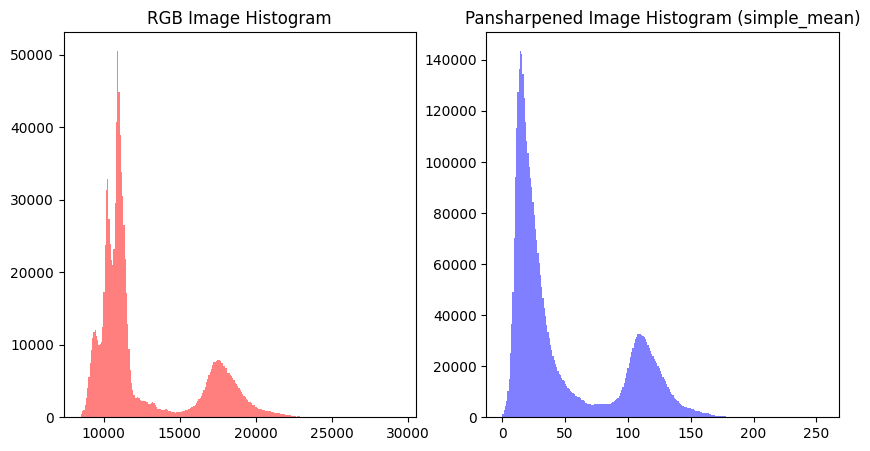

In [3]:
# Histograms
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("RGB Image Histogram")
plt.hist(rgb_image.ravel(), bins=256, color='r', alpha=0.5)
plt.subplot(1, 2, 2)
plt.title("Pansharpened Image Histogram (simple_mean)")
plt.hist(pansharpened_image.ravel(), bins=256, color='b', alpha=0.5)
plt.show()



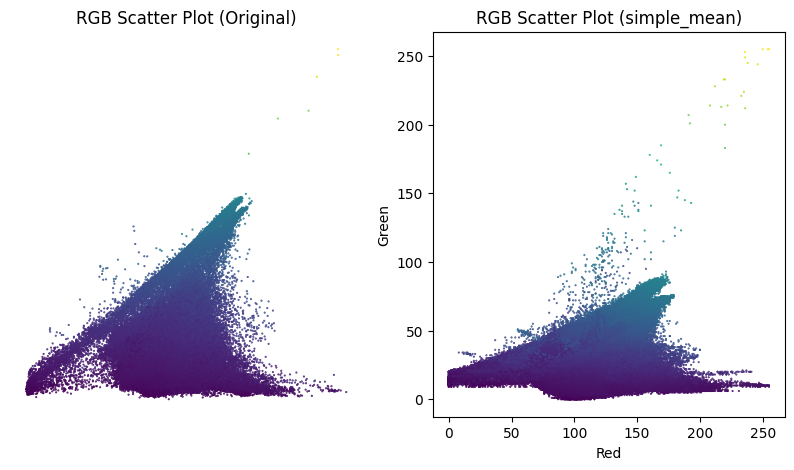

In [4]:
# RGB Scatter Plots
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("RGB Scatter Plot (Original)")
plt.scatter(rgb_image[..., 0], rgb_image[..., 1], c=rgb_image[..., 2], s=1, marker='.')
plt.axis("off")
plt.xlabel('Red')
plt.ylabel('Green')
plt.subplot(1, 2, 2)
plt.title("RGB Scatter Plot (simple_mean)")
plt.scatter(pansharpened_image[..., 0], pansharpened_image[..., 1], c=pansharpened_image[..., 2], s=1, marker='.')
plt.xlabel('Red')
plt.ylabel('Green')
plt.show()


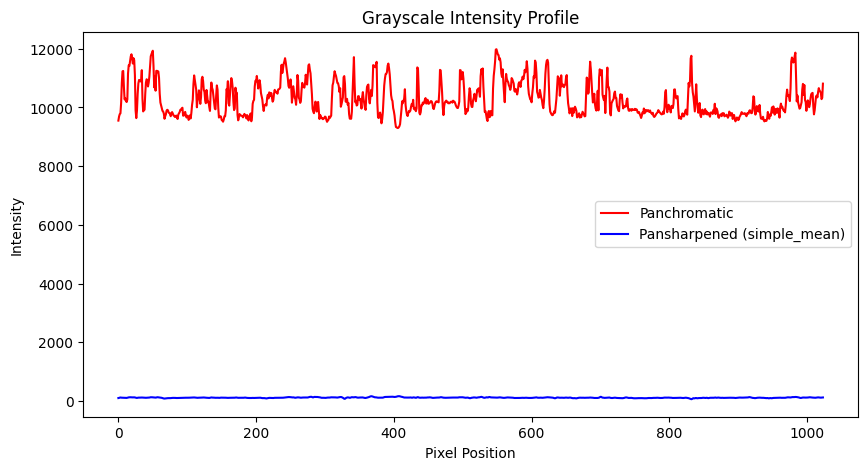

In [5]:
# Grayscale Intensity Profiles
# Extract intensity profiles (assuming you want the middle row)
middle_row = panchromatic_image.shape[0] // 2
y_panchromatic = panchromatic_image[middle_row, :]  # Entire middle row from pan_image

# Extract first channel (assuming grayscale for panchromatic)
y_pansharpened = pansharpened_image[middle_row, :, 0]  # Middle row, all columns, first channel

x = np.arange(panchromatic_image.shape[1])  # Create x-axis with same length as panchromatic profile

plt.figure(figsize=(10, 5))
plt.plot(x, y_panchromatic, 'r-', label='Panchromatic')
plt.plot(x, y_pansharpened, 'b-', label='Pansharpened (simple_mean)')
plt.title('Grayscale Intensity Profile')
plt.xlabel('Pixel Position')
plt.ylabel('Intensity')
plt.legend()
plt.show()

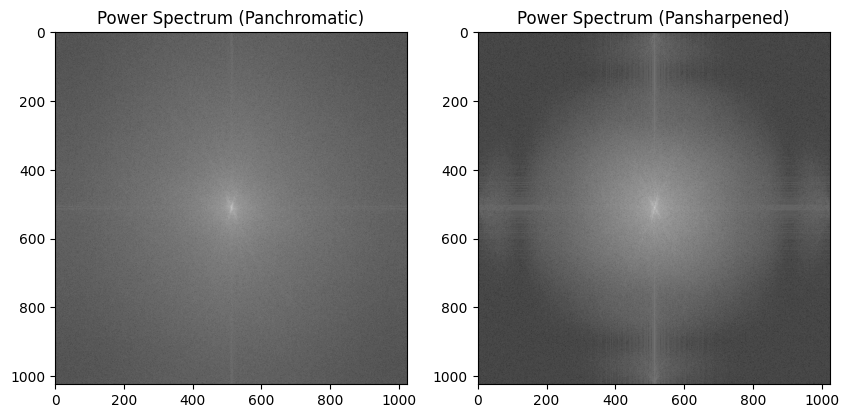

In [6]:
# Spatial Frequency Analysis
fft_panchromatic = np.fft.fft2(panchromatic_image)
fft_pansharpened = np.fft.fft2(pansharpened_image[..., 0])  # Assuming only analyzing one channel
power_spectrum_panchromatic = np.abs(fft_panchromatic)**2
power_spectrum_pansharpened = np.abs(fft_pansharpened)**2

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.log(1 + np.fft.fftshift(power_spectrum_panchromatic)), cmap='gray')
plt.title('Power Spectrum (Panchromatic)')
plt.subplot(1, 2, 2)
plt.imshow(np.log(1 + np.fft.fftshift(power_spectrum_pansharpened)), cmap='gray')
plt.title('Power Spectrum (Pansharpened)')
plt.show()


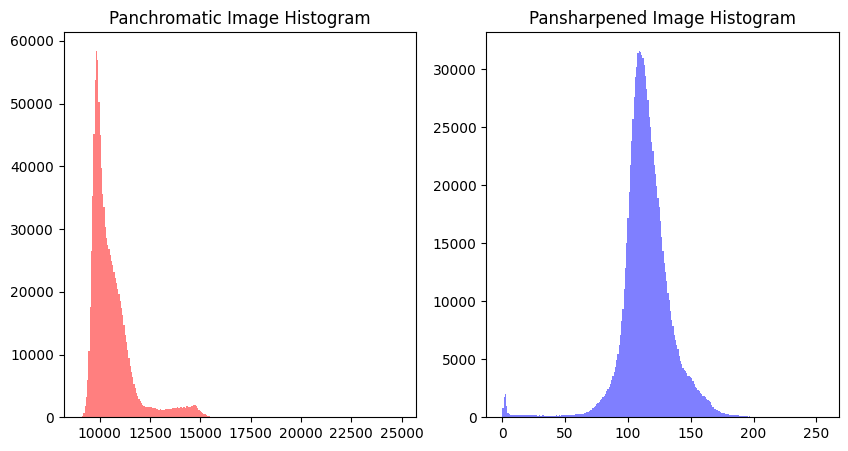

In [7]:
# Contrast Enhancement Analysis
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(panchromatic_image.ravel(), bins=256, color='r', alpha=0.5)
plt.title('Panchromatic Image Histogram')
plt.subplot(1, 2, 2)
plt.hist(pansharpened_image[..., 0].ravel(), bins=256, color='b', alpha=0.5)  # Assuming only analyzing one channel
plt.title('Pansharpened Image Histogram')
plt.show()

In [8]:
# # Difference Maps
# from skimage.transform import resize

# # Resize rgb_image to match the shape of pansharpened_image
# rgb_resized = resize(rgb_image, pansharpened_image.shape[:2], anti_aliasing=True)

# difference_map = np.abs(pansharpened_image.astype(np.float32) - rgb_resized.astype(np.float32))
# plt.figure(figsize=(10, 5))
# plt.imshow(difference_map)
# plt.title('Difference Map (Original - Pansharpened)')
# plt.colorbar()
# plt.show()


In [8]:
def bandwise_correlation(image1, image2):
    correlations = [np.corrcoef(image1[:, :, i].ravel(), image2[:, :, i].ravel())[0, 1] for i in range(image1.shape[2])]
    return correlations

# Assuming ms_image and pansharpened_image are your multispectral and pansharpened images
sam_value = 0.25328
correlation_values = bandwise_correlation(rgb_image, pansharpened_image)

# Plotting
plt.figure(figsize=(14, 6))

# SAM
plt.subplot(1, 2, 1)
plt.title("Spectral Angle Mapper (SAM)")
plt.bar(["SAM"], [sam_value], color='b')
plt.ylabel("SAM Value")

# Band-wise Correlation
plt.subplot(1, 2, 2)
plt.title("Band-wise Correlation")
bands = ['Red', 'Green', 'Blue', 'NIR']
plt.bar(bands, correlation_values, color='g')
plt.ylabel("Correlation Coefficient")

plt.tight_layout()
plt.show()

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 262144 and the array at index 1 has size 1048576

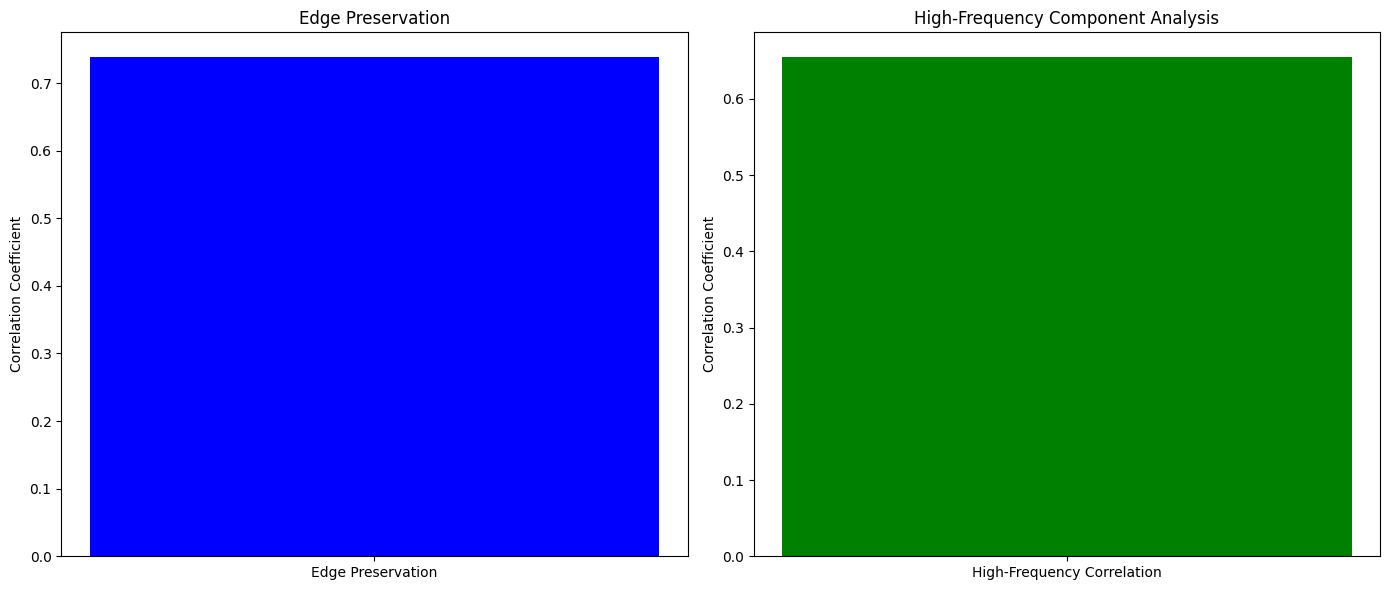

In [9]:
from skimage.filters import sobel
from scipy.signal import convolve2d

# Edge Preservation
def edge_preservation(image1, image2):
    edges1 = sobel(image1)
    edges2 = sobel(image2)
    correlation = np.corrcoef(edges1.ravel(), edges2.ravel())[0, 1]
    return correlation

# High-Frequency Component Analysis
def high_frequency_correlation(image1, image2):
    kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]])
    high_freq1 = convolve2d(image1, kernel, mode='same')
    high_freq2 = convolve2d(image2, kernel, mode='same')
    correlation = np.corrcoef(high_freq1.ravel(), high_freq2.ravel())[0, 1]
    return correlation

# Assuming pan_image and pansharpened_image_gray are your panchromatic and pansharpened grayscale images
# Convert pansharpened image to grayscale for spatial comparison
pansharpened_image_gray = np.mean(pansharpened_image, axis=2)

edge_corr = edge_preservation(panchromatic_image, pansharpened_image_gray)
high_freq_corr = high_frequency_correlation(panchromatic_image, pansharpened_image_gray)

# Plotting
plt.figure(figsize=(14, 6))

# Edge Preservation
plt.subplot(1, 2, 1)
plt.title("Edge Preservation")
plt.bar(["Edge Preservation"], [edge_corr], color='b')
plt.ylabel("Correlation Coefficient")

# High-Frequency Component Analysis
plt.subplot(1, 2, 2)
plt.title("High-Frequency Component Analysis")
plt.bar(["High-Frequency Correlation"], [high_freq_corr], color='g')
plt.ylabel("Correlation Coefficient")

plt.tight_layout()
plt.show()